In [1]:
import shapely
import shapefile
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy
import numpy as np
import datetime
import requests
import searvey

/home/jre/code/ngs_support/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Plot flight lines map

In [2]:
al_c = gpd.read_file('data/AL2401c-wpt.shp')
al_l = gpd.read_file('data/AL2401L-wpt.shp')

<GeoAxes: >

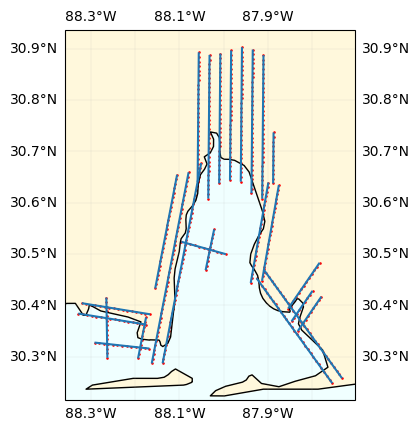

In [3]:
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines()
ax.add_feature(cartopy.feature.OCEAN, color="azure")
ax.add_feature(cartopy.feature.LAND, color="cornsilk")
ax.gridlines(draw_labels=True, linewidth=0.1)

al_l.plot(ax=ax)
al_c.plot(ax=ax, markersize=0.75, color='red')

# Plot map of nearby CO-OPS stations

In [4]:
bounds_c = al_c.total_bounds
bounds_l = al_l.total_bounds

In [5]:
lat_min = min(bounds_c[1], bounds_l[1])
lat_max = min(bounds_c[3], bounds_l[3])
lon_min = min(bounds_c[0], bounds_l[0])
lon_max = min(bounds_c[2], bounds_l[2])
print([lon_min, lon_max, lat_min, lat_max])

[np.float64(-88.32893096345423), np.float64(-87.73242486069674), np.float64(30.248288308761882), np.float64(30.902585471922464)]


In [6]:
stations = searvey.get_coops_stations(
    lon_min=lon_min,
    lon_max=lon_max,
    lat_min=lat_min,
    lat_max=lat_max,
    metadata_source='main'
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 28/28 [00:05<00:00,  5.60it/s]


In [7]:
waterlevel_stations = stations[(stations['status'] == 'active') & 
                               (stations['station_type'] == 'waterlevels')]
print(waterlevel_stations.name)

nos_id
8735180               Dauphin Island
8735391             Dog River Bridge
8735523       East Fowl River Bridge
8736897    Coast Guard Sector Mobile
8737048           Mobile State Docks
8737138              Chickasaw Creek
8738043       West Fowl River Bridge
8739803        Bayou La Batre Bridge
Name: name, dtype: string


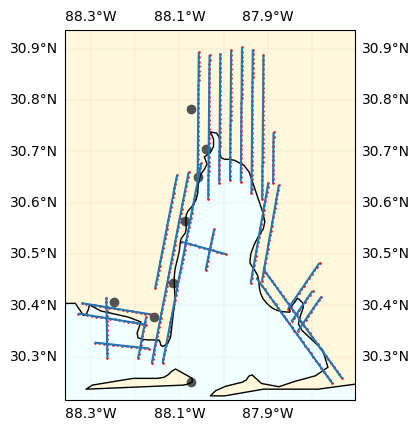

In [8]:
ax2 = plt.axes(projection=ccrs.PlateCarree())
ax2.coastlines()
ax2.add_feature(cartopy.feature.OCEAN, color="azure")
ax2.add_feature(cartopy.feature.LAND, color="cornsilk")
ax2.gridlines(draw_labels=True, linewidth=0.1)

al_l.plot(ax=ax2)
al_c.plot(ax=ax2, markersize=0.75, color='red')
ax2.scatter(waterlevel_stations.lon, waterlevel_stations.lat, c='#525252')

# Plot forecast water level time series

In [9]:
from importlib import reload
import stofs_run
import station_model
reload(stofs_run)
reload(station_model)

<module 'station_model' from '/home/jre/ngs-flight-planning/station_model.py'>

In [10]:
forecast_date = datetime.datetime(2024,12,15,12,0)
forecast_2d = stofs_run.stofs_2d.get_station_forecast(forecast_date)
forecast_2d.load()

<xarray.Dataset> Size: 25MB
Dimensions:       (time: 1860, station: 1688)
Coordinates:
  * time          (time) datetime64[ns] 15kB 2024-12-15T06:06:00 ... 2024-12-23
Dimensions without coordinates: station
Data variables:
    station_name  (station) |S50 84kB b'PSBM1 SOUS41 8410140 ME Eastport     ...
    x             (station) float64 14kB -66.98 -67.2 -68.2 ... -51.01 -25.5
    y             (station) float64 14kB 44.9 44.65 44.39 ... 58.96 58.96 58.96
    zeta          (time, station) float64 25MB -0.2341 -0.4647 ... 0.119 0.3179
Attributes: (12/50)
    dry_Value:          -99999.0
    model:              ADCIRC
    version:            noaa.stofs.2d.glo.v2.1.0r1.v55.12
    git_hash:           23947fbd9683d0ef48f12e6ce62d45d18bc27ff3
    grid_type:          Triangular
    description:        2024121512 :-6 hr nowcast and +180 hr forecast ! 32 C...
    ...                 ...
    sfea0:              45.0
    cf:                 0.0005
    eslm:               -0.2
    cori:               0.0
    ntif:               8
    nbfr:               0

In [11]:
forecast_stations = station_model.extract_model_station_df(forecast_2d, waterlevel_stations.index)

In [12]:
print(pd.unique(forecast_stations.index.get_level_values('station')))

['8735180' '8735391' '8736897' '8737048' '8737138']


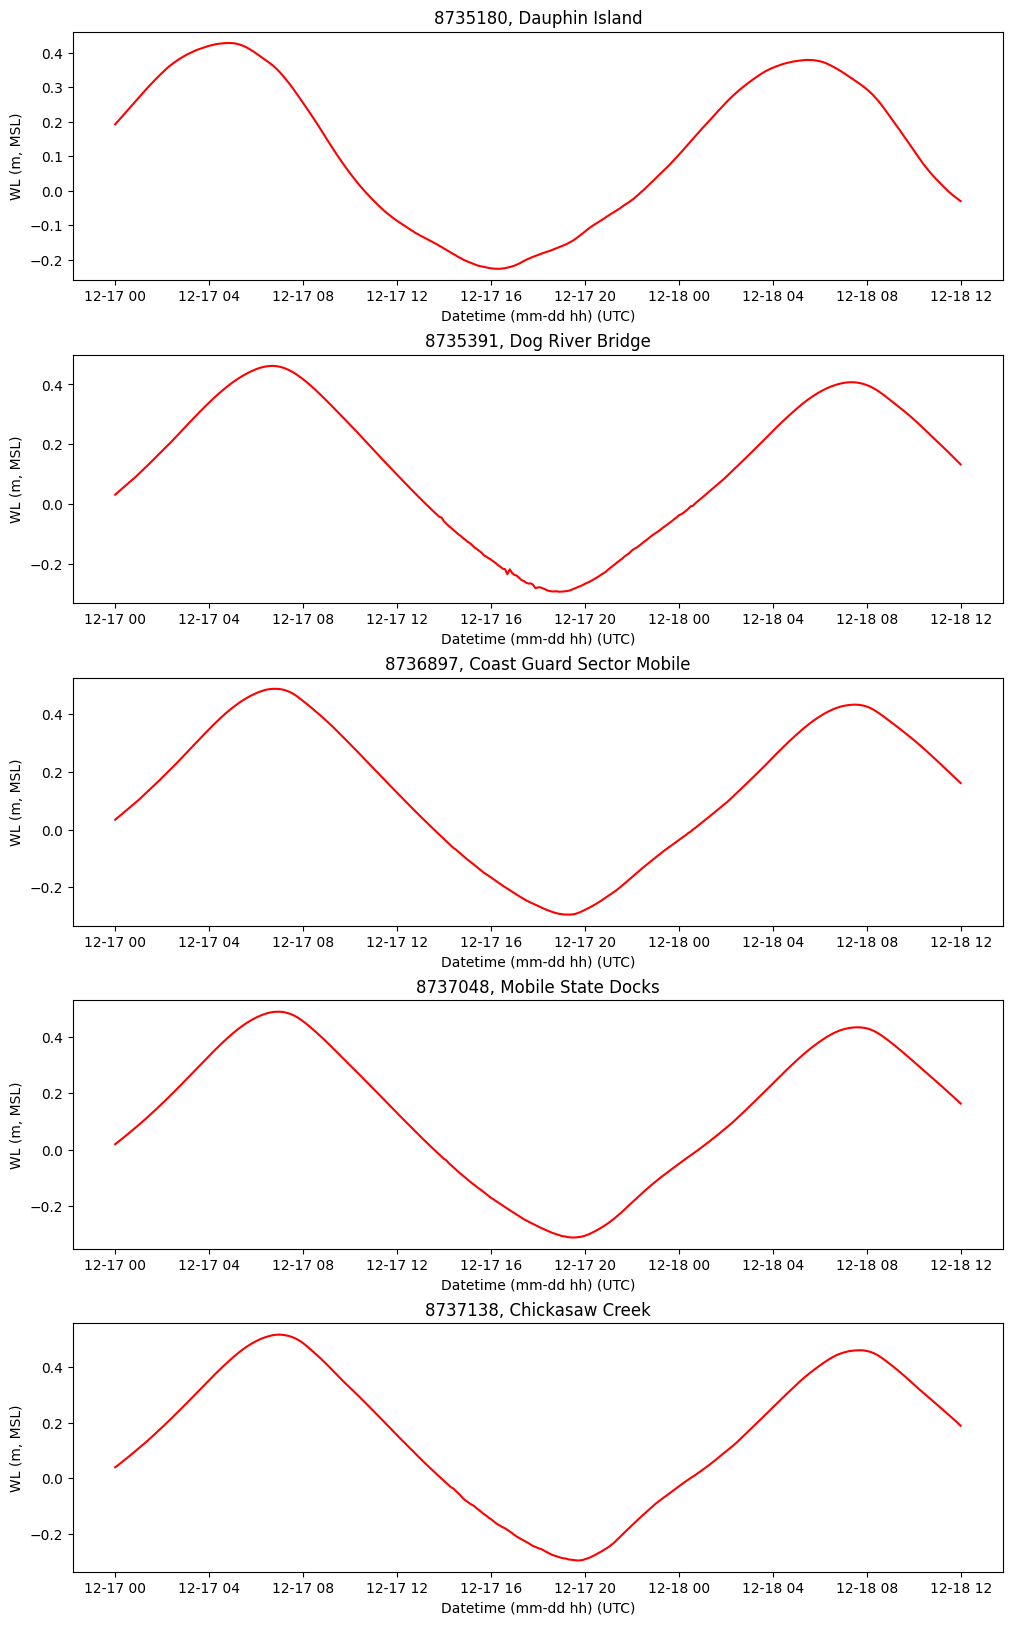

In [13]:
# Create a figure and axes array with subplots
fig, axs = plt.subplots(5, 1, 
                        figsize=(12, 20))
fig.subplots_adjust(hspace=0.3)
axs = axs.flatten()

timeslice = slice('2024-12-17 00:00:00',
                  '2024-12-18 12:00:00')

for ist, nos_id in enumerate(pd.unique(forecast_stations.index.get_level_values('station'))):
    
    if ist >= 5:
        break
    else:
        ax = axs[ist]

    try:
        ax.plot(forecast_stations.loc[nos_id].loc[timeslice].index, 
                forecast_stations.loc[nos_id].loc[timeslice]['zeta'], 
                label='STOFS-2D-Global',color='red')
    except:
        print(f"Cannot plot STOFS-2D nowcast data for NOS ID {nos_id}")
        
    ax.set_xlabel('Datetime (mm-dd hh) (UTC)')
    ax.set_ylabel('WL (m, MSL)')
    ax.set_title(nos_id + ', ' + waterlevel_stations.name[nos_id])
    
plt.show()

# Get datum information and plot tolerances on time series

In [14]:
# Sample API request:
# https://api.tidesandcurrents.noaa.gov/mdapi/prod/webapi/stations/8735180/datums.json?units=metric
# from:
# https://tidesandcurrents.noaa.gov/api-helper/url-generator.html

In [15]:
def get_station_datums(nos_id):
    url = f'https://api.tidesandcurrents.noaa.gov/mdapi/prod/webapi/stations/{nos_id}/datums.json?units=metric'
    r = requests.get(url)
    full_dict = r.json()
    datum_dict = {dd['name']:dd['value'] for dd in full_dict['datums']}
    return datum_dict

In [16]:
def get_datum_bounds(datum_dict, base_datum, pm_bounds):
    result = {}
    for k in datum_dict.keys():
        result[k] = {'upper': datum_dict[k] - datum_dict[base_datum] + pm_bounds,
                     'lower': datum_dict[k] - datum_dict[base_datum] - pm_bounds}
    return result

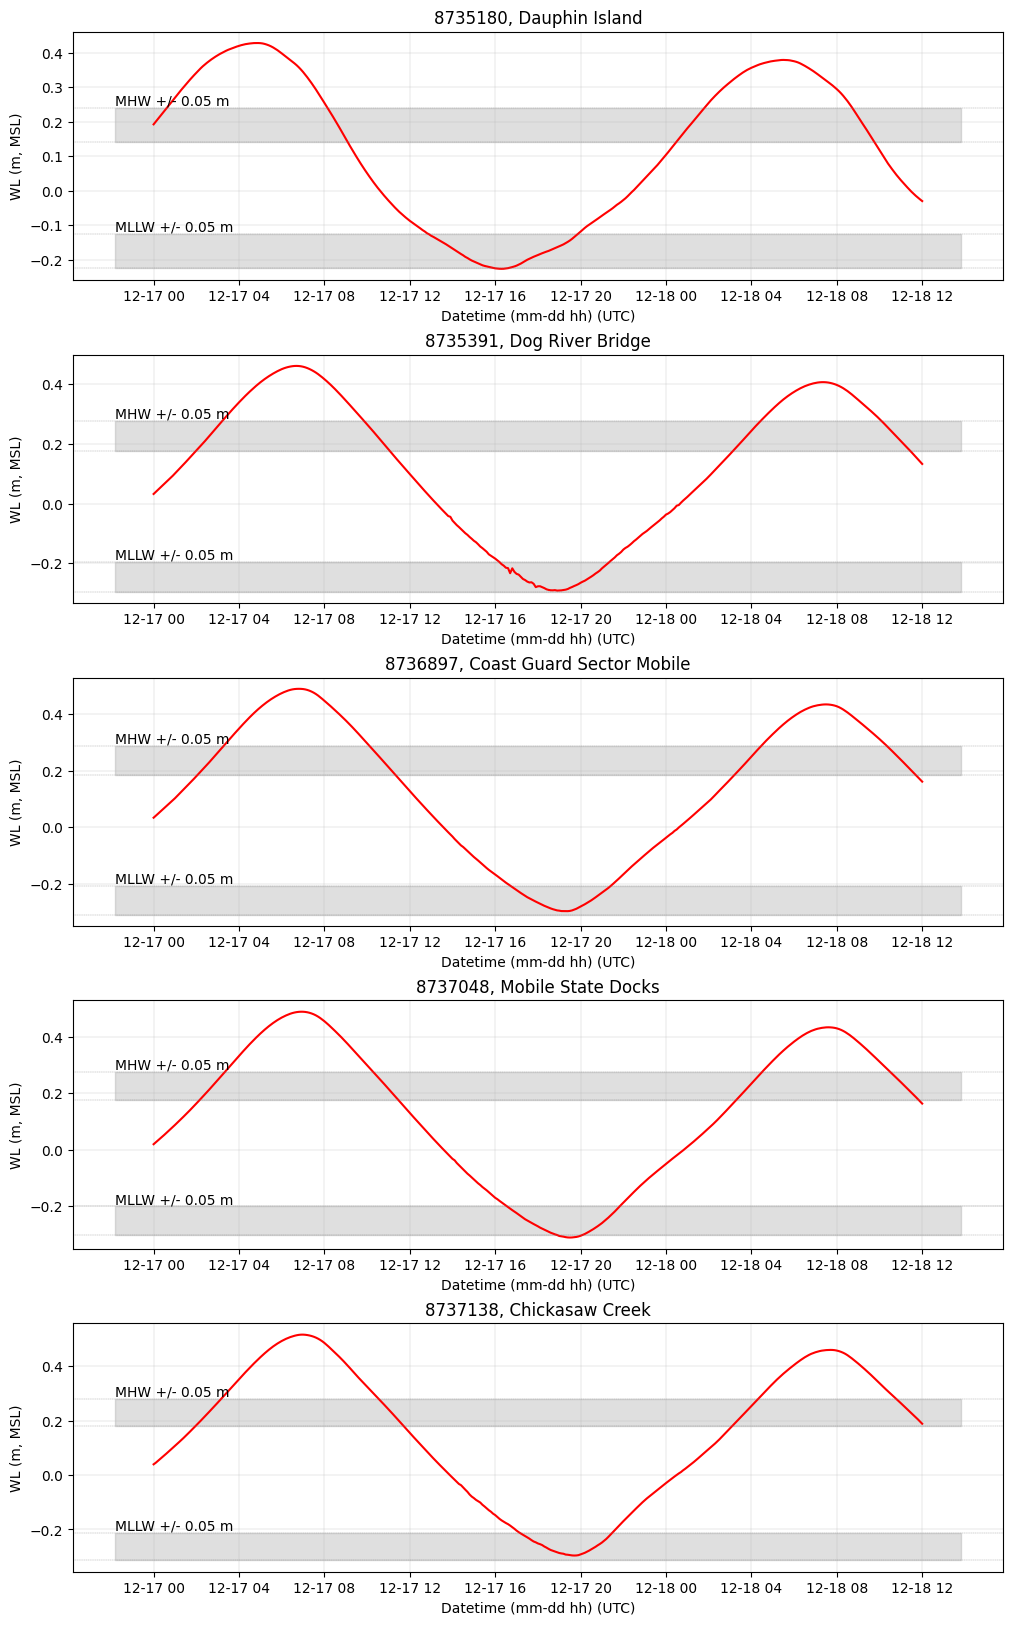

In [17]:
# Create a figure and axes array with subplots
fig, axs = plt.subplots(5, 1, 
                        figsize=(12, 20))
fig.subplots_adjust(hspace=0.3)
axs = axs.flatten()

time_range = ['2024-12-17 00:00:00',
              '2024-12-18 12:00:00']
timeslice = slice(time_range[0], time_range[1])
datum_tol = 0.05

for ist, nos_id in enumerate(pd.unique(forecast_stations.index.get_level_values('station'))):
    
    if ist >= 5:
        break
    
    ax = axs[ist]
    
    datum_dict = get_station_datums(nos_id)
    datum_bounds = get_datum_bounds(datum_dict, 'MSL', datum_tol)

    try:
        ax.plot(forecast_stations.loc[nos_id].loc[timeslice].index, 
                forecast_stations.loc[nos_id].loc[timeslice]['zeta'], 
                label='STOFS-2D-Global',color='red')
        xlims = ax.get_xlim()
        for dat in ['MLLW', 'MHW']:
            ax.axhline(y = datum_bounds[dat]['upper'], 
                       linestyle='--', linewidth=0.25, color='gray')
            ax.axhline(y = datum_bounds[dat]['lower'],
                       linestyle='--', linewidth=0.25, color='gray')
            ax.fill_between(xlims, 
                            [datum_bounds[dat]['upper'], datum_bounds[dat]['upper']],
                            [datum_bounds[dat]['lower'], datum_bounds[dat]['lower']],
                            color='gray', alpha=0.25)
            ax.text(xlims[0], 
                    datum_bounds[dat]['upper'], 
                    f'{dat} +/- {datum_tol} m',
                    va='bottom')
    except:
        print(f"Cannot plot STOFS-2D nowcast data for NOS ID {nos_id}")
        
    ax.set_xlabel('Datetime (mm-dd hh) (UTC)')
    ax.set_ylabel('WL (m, MSL)')
    ax.set_title(nos_id + ', ' + waterlevel_stations.name[nos_id])
    ax.grid(linewidth=0.2)
    
plt.show()